# Mixture Density Network (MDN) - PyTorch 实现

## 问题设定
我们要学习这样一个目标函数：
$$x = t + 0.3 \sin(2\pi t) + \text{noise}$$

**核心挑战**：给定输入 $t$，同一个 $t$ 值可能对应多个 $x$ 值（由于噪声）。传统神经网络只能输出单一值，无法捕捉这种**多模式分布**。

## 解决方案：混合密度网络
- 不直接预测 $x$，而是预测 **条件概率分布** $p(x|t)$
- 用 **K 个高斯分量的混合** 来建模这个分布
- 神经网络输出：
  - 权重 $\pi_k(t)$：各分量的混合比例
  - 均值 $\mu_k(t)$：各分量的中心
  - 方差 $\sigma_k(t)$：各分量的宽度

## 似然函数（损失函数）
$$L = -\ln p(x|t) = -\ln \sum_{k=1}^{K} \pi_k(t) \mathcal{N}(x|\mu_k(t), \sigma_k(t)^2)$$

其中高斯分量为：
$$\mathcal{N}(x|\mu_k, \sigma_k^2) = \frac{1}{\sqrt{2\pi\sigma_k^2}} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$$

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import warnings
warnings.filterwarnings('ignore')


# 设置随机种子
torch.manual_seed(42)
np.random.seed(42)

print("✓ 导入完成")

✓ 导入完成


## 步骤 1：生成训练数据

In [2]:
# 生成数据
n_samples = 1000
t_train = np.random.uniform(-1, 1, n_samples)
x_train = t_train + 0.3 * np.sin(2 * np.pi * t_train) + np.random.normal(0, 0.1, n_samples)

# 生成测试数据（等间距）
t_test = np.linspace(-1, 1, 100)
x_test = t_test + 0.3 * np.sin(2 * np.pi * t_test) + np.random.normal(0, 0.1, 100)

# 转换为 PyTorch 张量
t_train_tensor = torch.FloatTensor(t_train).reshape(-1, 1)
x_train_tensor = torch.FloatTensor(x_train).reshape(-1, 1)
t_test_tensor = torch.FloatTensor(t_test).reshape(-1, 1)
x_test_tensor = torch.FloatTensor(x_test).reshape(-1, 1)

print(f"✓ 数据生成完成")
print(f"  训练集大小: {t_train_tensor.shape[0]}")
print(f"  t 范围: [{t_train.min():.2f}, {t_train.max():.2f}]")
print(f"  x 范围: [{x_train.min():.2f}, {x_train.max():.2f}]")

✓ 数据生成完成
  训练集大小: 1000
  t 范围: [-0.99, 1.00]
  x 范围: [-1.11, 1.12]


## 可视化原始数据

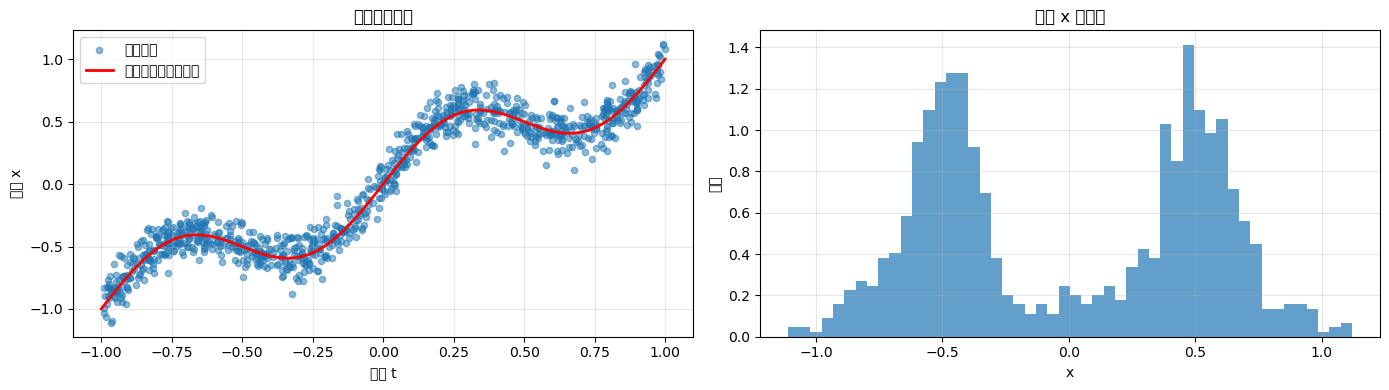

✓ 数据可视化完成


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 散点图
axes[0].scatter(t_train, x_train, alpha=0.5, s=20, label='训练数据')
# 理想曲线
t_ideal = np.linspace(-1, 1, 200)
x_ideal = t_ideal + 0.3 * np.sin(2 * np.pi * t_ideal)
axes[0].plot(t_ideal, x_ideal, 'r-', linewidth=2, label='目标函数（无噪声）')
axes[0].set_xlabel('输入 t')
axes[0].set_ylabel('输出 x')
axes[0].set_title('训练数据分布')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 分布直方图
axes[1].hist(x_train, bins=50, alpha=0.7, density=True)
axes[1].set_xlabel('x')
axes[1].set_ylabel('密度')
axes[1].set_title('输出 x 的分布')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("✓ 数据可视化完成")

## 步骤 2：定义 MDN 网络架构

In [ ]:
class MixtureDensityNetwork(nn.Module):
    """混合密度网络：预测条件概率分布而不是单个值"""
    
    def __init__(self, input_dim=1, hidden_dim=32, n_components=3):
        super().__init__()
        self.n_components = n_components
        
        # 共享的隐藏层
        self.hidden_layer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        
        # 输出层：预测混合权重、均值和方差
        # 权重需要经过 softmax 确保求和为 1
        self.pi_layer = nn.Linear(hidden_dim, n_components)  # softmax 后
        
        # 均值层（无约束）
        self.mu_layer = nn.Linear(hidden_dim, n_components)
        
        # 方差层：用 exp 保证为正
        self.sigma_layer = nn.Linear(hidden_dim, n_components)
    
    def forward(self, t):
        """
        输入: t (batch_size, 1)
        输出:
            pi: (batch_size, n_components) - 混合权重 [0, 1] 且求和为 1
            mu: (batch_size, n_components) - 高斯均值
            sigma: (batch_size, n_components) - 高斯方差 (正数)
        """
        h = self.hidden_layer(t)  # (batch_size, hidden_dim)
        
        # 计算混合权重（softmax 确保非负且求和为 1）
        pi = torch.softmax(self.pi_layer(h), dim=1)  # (batch_size, n_components)
        
        # 计算均值（无约束）
        mu = self.mu_layer(h)  # (batch_size, n_components)
        
        # 计算方差（exp 确保为正）
        sigma = torch.exp(self.sigma_layer(h))  # (batch_size, n_components)
        
        return pi, mu, sigma

print("✓ MDN 模型定义完成")

## 步骤 3：定义似然函数（损失函数）

In [ ]:
def mdn_loss(pi, mu, sigma, x_target):
    """
    计算 MDN 的负对数似然损失
    
    参数:
        pi: (batch_size, n_components) - 混合权重
        mu: (batch_size, n_components) - 高斯均值
        sigma: (batch_size, n_components) - 高斯方差
        x_target: (batch_size, 1) - 目标输出
    
    返回:
        loss: 标量，负对数似然
    """
    batch_size = x_target.shape[0]
    n_components = pi.shape[1]
    
    # 扩展 x_target 以匹配分量维度
    x_expanded = x_target.expand(batch_size, n_components)  # (batch_size, n_components)
    
    # 计算每个高斯分量的 PDF
    # N(x|μ_k, σ_k²) = (1/√(2πσ_k²)) * exp(-(x-μ_k)²/(2σ_k²))
    gaussian_pdf = (1.0 / (sigma * torch.sqrt(torch.tensor(2 * np.pi)))) * \
                   torch.exp(-0.5 * ((x_expanded - mu) / sigma) ** 2)
    
    # 混合分布的 PDF
    # p(x|t) = Σ_k π_k * N(x|μ_k, σ_k²)
    mixture_pdf = torch.sum(pi * gaussian_pdf, dim=1)  # (batch_size,)
    
    # 负对数似然
    # L = -ln(p(x|t))
    loss = -torch.log(mixture_pdf + 1e-6).mean()  # 加小值避免 log(0)
    
    return loss

print("✓ 损失函数定义完成")

## 步骤 4：模型训练

In [ ]:
# 创建模型
n_components = 3  # 使用 3 个高斯分量
model = MixtureDensityNetwork(input_dim=1, hidden_dim=32, n_components=n_components)

# 优化器
optimizer = optim.Adam(model.parameters(), lr=0.01)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.9)

# 训练参数
n_epochs = 300
batch_size = 64

# 记录损失
losses = []

# 训练循环
print("开始训练...")
for epoch in range(n_epochs):
    # 随机打乱训练数据
    indices = torch.randperm(t_train_tensor.shape[0])
    
    epoch_loss = 0
    n_batches = 0
    
    for i in range(0, len(indices), batch_size):
        batch_idx = indices[i:i+batch_size]
        t_batch = t_train_tensor[batch_idx]
        x_batch = x_train_tensor[batch_idx]
        
        # 前向传播
        pi, mu, sigma = model(t_batch)
        
        # 计算损失
        loss = mdn_loss(pi, mu, sigma, x_batch)
        
        # 反向传播
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        n_batches += 1
    
    scheduler.step()
    avg_loss = epoch_loss / n_batches
    losses.append(avg_loss)
    
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/{n_epochs} | Loss: {avg_loss:.4f}")

print("✓ 训练完成")

## 训练曲线

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(losses, linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('负对数似然损失')
ax.set_title('训练曲线')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"✓ 最终损失: {losses[-1]:.4f}")

## 步骤 5：生成预测分布

In [ ]:
# 在均匀间距点上进行预测
t_pred = np.linspace(-1, 1, 50)
t_pred_tensor = torch.FloatTensor(t_pred).reshape(-1, 1)

with torch.no_grad():
    pi_pred, mu_pred, sigma_pred = model(t_pred_tensor)
    
pi_pred = pi_pred.numpy()
mu_pred = mu_pred.numpy()
sigma_pred = sigma_pred.numpy()

print("✓ 预测完成")
print(f"\n混合权重 π 的范围:")
for k in range(n_components):
    print(f"  分量 {k}: [{pi_pred[:, k].min():.4f}, {pi_pred[:, k].max():.4f}]")

## 步骤 6：可视化预测结果

In [ ]:
# 为每个预测点生成 x 的采样
def sample_from_mdn(pi, mu, sigma, n_samples=1000):
    """
    从学到的混合分布中采样
    
    参数:
        pi: (n_points, n_components) - 混合权重
        mu: (n_points, n_components) - 均值
        sigma: (n_points, n_components) - 方差
        n_samples: 每个 t 值采样多少个 x
    
    返回:
        samples: (n_points, n_samples, 2) - [t, x] 对
    """
    n_points = pi.shape[0]
    n_components = pi.shape[1]
    samples = np.zeros((n_points, n_samples, 2))
    
    for i in range(n_points):
        # 根据混合权重选择分量
        component_idx = np.random.choice(n_components, size=n_samples, p=pi[i])
        
        # 从对应的高斯分量采样
        for j in range(n_samples):
            k = component_idx[j]
            x_sample = np.random.normal(mu[i, k], sigma[i, k])
            samples[i, j, 0] = t_pred[i]
            samples[i, j, 1] = x_sample
    
    return samples

samples = sample_from_mdn(pi_pred, mu_pred, sigma_pred, n_samples=500)
print(f"✓ 采样完成: {samples.shape}")

## 可视化：预测分布 vs 真实数据

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 子图 1: 原始数据与采样点
ax = axes[0, 0]
ax.scatter(t_train, x_train, alpha=0.3, s=10, label='训练数据', color='blue')
ax.scatter(samples[:, :, 0], samples[:, :, 1], alpha=0.2, s=10, label='MDN 采样点', color='orange')
t_ideal = np.linspace(-1, 1, 200)
x_ideal = t_ideal + 0.3 * np.sin(2 * np.pi * t_ideal)
ax.plot(t_ideal, x_ideal, 'r-', linewidth=2, label='目标函数')
ax.set_xlabel('t')
ax.set_ylabel('x')
ax.set_title('预测分布 vs 真实数据')
ax.legend()
ax.grid(True, alpha=0.3)

# 子图 2: 混合权重 π
ax = axes[0, 1]
for k in range(n_components):
    ax.plot(t_pred, pi_pred[:, k], linewidth=2, label=f'分量 {k}')
ax.set_xlabel('t')
ax.set_ylabel('混合权重 π')
ax.set_title('各分量的混合权重')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1])

# 子图 3: 均值 μ
ax = axes[1, 0]
for k in range(n_components):
    ax.plot(t_pred, mu_pred[:, k], linewidth=2, marker='o', markersize=3, label=f'分量 {k}')
t_ideal = np.linspace(-1, 1, 200)
x_ideal = t_ideal + 0.3 * np.sin(2 * np.pi * t_ideal)
ax.plot(t_ideal, x_ideal, 'k--', linewidth=2, label='真实函数')
ax.set_xlabel('t')
ax.set_ylabel('均值 μ')
ax.set_title('各分量的中心位置')
ax.legend()
ax.grid(True, alpha=0.3)

# 子图 4: 方差 σ
ax = axes[1, 1]
for k in range(n_components):
    ax.plot(t_pred, sigma_pred[:, k], linewidth=2, label=f'分量 {k}')
ax.set_xlabel('t')
ax.set_ylabel('方差 σ')
ax.set_title('各分量的宽度')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim([0, None])

plt.tight_layout()
plt.show()
print("✓ 四子图可视化完成")

## 步骤 7：条件概率密度的热力图

In [ ]:
def compute_conditional_pdf(t_vals, x_vals, pi, mu, sigma):
    """
    计算条件概率密度 p(x|t)
    
    参数:
        t_vals: 预测点的 t 值
        x_vals: 评估点的 x 值
        pi, mu, sigma: 模型输出
    
    返回:
        pdf: (len(t_vals), len(x_vals)) 的密度矩阵
    """
    pdf = np.zeros((len(t_vals), len(x_vals)))
    
    for i, t_val in enumerate(t_vals):
        for j, x_val in enumerate(x_vals):
            # 计算混合分布的 PDF
            mixture = 0
            for k in range(n_components):
                # 高斯分量
                gaussian = (1.0 / (sigma[i, k] * np.sqrt(2 * np.pi))) * \
                          np.exp(-0.5 * ((x_val - mu[i, k]) / sigma[i, k]) ** 2)
                mixture += pi[i, k] * gaussian
            pdf[i, j] = mixture
    
    return pdf

# 计算热力图
t_heat = np.linspace(-1, 1, 100)
x_heat = np.linspace(-0.5, 2.5, 100)

# 需要在热力图对应的 t 值处进行模型预测
t_heat_tensor = torch.FloatTensor(t_heat).reshape(-1, 1)
with torch.no_grad():
    pi_heat, mu_heat, sigma_heat = model(t_heat_tensor)
    
pi_heat = pi_heat.numpy()
mu_heat = mu_heat.numpy()
sigma_heat = sigma_heat.numpy()

# 计算 PDF
pdf_heat = compute_conditional_pdf(t_heat, x_heat, pi_heat, mu_heat, sigma_heat)

print(f"✓ 热力图数据计算完成: {pdf_heat.shape}")

## 条件概率密度热力图

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 热力图
im = ax1.contourf(t_heat, x_heat, pdf_heat.T, levels=20, cmap='viridis')
ax1.scatter(t_train, x_train, alpha=0.5, s=20, color='red', edgecolors='white', linewidths=0.5, label='训练数据')
ax1.set_xlabel('输入 t')
ax1.set_ylabel('输出 x')
ax1.set_title('条件概率密度 p(x|t) - 热力图')
ax1.legend()
plt.colorbar(im, ax=ax1, label='概率密度')

# 在几个特定 t 值处画出条件分布
t_specific = [-0.5, 0, 0.5]
colors = ['red', 'blue', 'green']

for t_val, color in zip(t_specific, colors):
    # 找到最近的 t_heat 索引
    idx = np.argmin(np.abs(t_heat - t_val))
    pdf_1d = pdf_heat[idx, :]
    ax2.plot(x_heat, pdf_1d, linewidth=2, label=f't={t_val:.1f}', color=color)

ax2.set_xlabel('输出 x')
ax2.set_ylabel('概率密度')
ax2.set_title('不同 t 值下的条件分布 p(x|t)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("✓ 条件概率密度可视化完成")

## 步骤 8：验证和分析

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 在测试集上评估
with torch.no_grad():
    pi_test, mu_test, sigma_test = model(t_test_tensor)
    test_loss = mdn_loss(pi_test, mu_test, sigma_test, x_test_tensor)

print(f"\n=== 最终评估 ===")
print(f"训练集负对数似然: {losses[-1]:.4f}")
print(f"测试集负对数似然: {test_loss.item():.4f}")

# 子图 1: 在测试点预测的均值
ax = axes[0]
mu_test_pred = mu_test.numpy()
idx_max_pi = np.argmax(pi_test.numpy(), axis=1)
mu_best = np.array([mu_test_pred[i, idx_max_pi[i]] for i in range(len(idx_max_pi))])

ax.scatter(t_test, x_test, alpha=0.5, s=20, label='测试数据', color='blue')
ax.plot(t_test, mu_best, 'r-', linewidth=2, label='最优分量的均值')
t_ideal = np.linspace(-1, 1, 200)
x_ideal = t_ideal + 0.3 * np.sin(2 * np.pi * t_ideal)
ax.plot(t_ideal, x_ideal, 'k--', linewidth=2, alpha=0.7, label='目标函数')
ax.set_xlabel('t')
ax.set_ylabel('x')
ax.set_title('最优分量均值 vs 测试数据')
ax.legend()
ax.grid(True, alpha=0.3)

# 子图 2: 方差范围（作为不确定性度量）
ax = axes[1]
sigma_test = sigma_test.numpy()
sigma_mean = np.mean(sigma_test, axis=1)  # 平均方差
sigma_std = np.std(sigma_test, axis=1)    # 方差的标准差

ax.scatter(t_test, x_test, alpha=0.5, s=20, label='测试数据')
ax.plot(t_test, mu_best, 'r-', linewidth=2, label='均值')
ax.fill_between(t_test, mu_best - 2*sigma_mean, mu_best + 2*sigma_mean, 
                 alpha=0.3, color='red', label='±2σ 置信区间')
ax.set_xlabel('t')
ax.set_ylabel('x')
ax.set_title('预测不确定性（方差）')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 关键要点总结

In [ ]:
print("""
╔════════════════════════════════════════════════════════════════╗
║             混合密度网络 (MDN) 学习要点总结                    ║
╚════════════════════════════════════════════════════════════════╝

1. 问题定义
   ─────────────────────────────────────────────────────────────
   • 单一输入 t 对应多个输出 x（由于噪声）
   • 传统网络无法捕捉一对多的映射关系
   • 需要用概率分布而不是单个值来建模

2. 核心思想：从点预测到分布预测
   ─────────────────────────────────────────────────────────────
   • 传统方式：t → [神经网络] → x (单个值)
   • MDN 方式：t → [神经网络] → p(x|t) (完整分布)
   • 用 K 个高斯分量的混合来表示 p(x|t)

3. 网络输出（参数）
   ─────────────────────────────────────────────────────────────
   • π_k(t): 混合权重 → 通过 softmax 确保 [0,1] 且 Σπ_k=1
   • μ_k(t): 高斯均值 → 无约束
   • σ_k(t): 高斯方差 → 通过 exp() 确保为正

4. 损失函数：负对数似然 (NLL)
   ─────────────────────────────────────────────────────────────
   L = -ln p(x|t) = -ln Σ_k π_k·𝒩(x|μ_k, σ_k²)
   
   直观解释：
   • 实际的 x 在模型分布中概率越高 → 损失越低
   • 实际的 x 在模型分布中概率越低 → 损失越高

5. 训练后的效果
   ─────────────────────────────────────────────────────────────
   ✓ 可以从学到的分布中采样，得到多样的预测
   ✓ 可以评估特定预测的不确定性（通过方差）
   ✓ 可以计算任意 (t, x) 对的概率
   ✓ 在复杂、多模态的数据上表现优异

6. 与其他方法的对比
   ─────────────────────────────────────────────────────────────
   • MSE 损失：无法处理多模态，只能给出平均值
   • 分类模型：离散化了连续分布
   • MDN：原生支持连续的、多模态的条件分布

7. 应用场景
   ─────────────────────────────────────────────────────────────
   • 手写体识别（一个笔画可能对应多个字符）
   • 机器人逆运动学（一个末端位置对应多个关节配置）
   • 语音合成（一个文本对应多种发音方式）
   • 任何一对多的映射问题

8. 参数解释
   ─────────────────────────────────────────────────────────────
""")

print(f"\n本例中的配置：")
print(f"  • 分量数量：{n_components}")
print(f"  • 网络结构：1 → 32 → 32 → {n_components}×3 输出")
print(f"  • 训练样本：{len(t_train)} 个")
print(f"  • 最终损失：{losses[-1]:.4f}")

## 扩展思考

**你可以尝试的改进：**
1. 增加分量数量（n_components=5）看效果是否更好
2. 改变网络结构（更深或更宽）
3. 调整噪声水平，看模型如何适应
4. 在新的 t 值上做预测，可视化完整的条件分布
5. 比较不同初始化对训练的影响
6. 实现 dropout 或其他正则化方法

**理论深化：**
- 为什么是混合高斯而不是其他分布？
- 如何确定最优的分量数量？
- 负对数似然与其他信息论指标（如 KL 散度）的关系
- MDN 与变分自编码器 (VAE) 的联系